# 兴登堡预兆（Hindenburg Omen）A 股复现：完整走读

这个 notebook 从头到尾演示一遍研究过程，所有计算都调用项目里的 `.py` 模块，不重复实现逻辑：

1. 指标定义
2. 加载数据，计算市场宽度
3. 四个条件与信号
4. 信号聚成集群，计算后续回撤
5. **命中率 vs 基准率**（核心结论）
6. 案例：2015 年为什么没有信号
7. 五个指数汇总
8. 结论与局限

> 日常更新数据、生成仪表盘请用命令行 `python hindenburg.py ...`，见 README。

## 0. 环境设置

数据默认在 `data/`。如果放在别处，在导入项目模块**之前**设置环境变量 `HO_DATA_DIR`。
`HO_OFFLINE=1` 表示只用本地数据、不连聚宽。

In [1]:
import os
# os.environ['HO_DATA_DIR'] = '/path/to/your/data'   # 数据不在 data/ 时取消注释
os.environ.setdefault('HO_OFFLINE', '1')

import pandas as pd
import matplotlib.pyplot as plt

import config
from config import STRATEGIES
from data import Panel, BreadthCache
from backtest import build_clusters, evaluate, summarize
from hindenburg import Omen, _make_store

plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Heiti SC',
                                   'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

## 1. 指标定义

四个条件**同一天全部满足**才算一次信号：

| | 条件 | 默认参数 |
|---|---|---|
| ① | 趋势向上：50 日均线在上升，`MA(t) > MA(t-5)` | `ma_period=50, ma_lookback=5` |
| ② | 创 52 周新高、新低的股票占比**都** ≥ 2.2% | `threshold=0.022` |
| ③ | 新高家数 ≤ 新低家数 × 2 | `hl_ratio=2.0` |
| ④ | McClellan 振荡器 < 0（涨跌家数差的 EMA19 − EMA39） | `ema_short=19, ema_long=39` |

直觉：大盘还在涨（①），但内部严重分化，大量股票同时在创新高和新低（②③），而且涨跌家数的动量已经转弱（④）。

**集群**：36 个交易日内出现 ≥ 2 次信号，升级为「有效集群」。回撤从**确认日**（第 2 次信号那天）起算，避免前视偏差。

## 2. 加载数据，计算市场宽度

以中证全指为例。`Omen.compute()` 会：
- 按可交易域规则（当天有成交、上市满一年）确定每天的股票池；
- 计算 52 周新高 / 新低家数和 McClellan 振荡器（有缓存时直接读取）；
- 读取基准指数收盘价，算出四个条件。

In [2]:
s = STRATEGIES['ashare']
p = s.params
panel = Panel(state_rule=s.state_rule, exclude_boards=p.exclude_boards,
              include_exchanges=p.include_exchanges)
end = panel.last_date.strftime('%Y-%m-%d')

omen = Omen(s, panel, _make_store(), BreadthCache())
df = omen.compute(s.start, end)

print(f'{s.name}（{s.benchmark}）  {df.index[0]:%Y-%m-%d} ~ {df.index[-1]:%Y-%m-%d}，共 {len(df):,} 个交易日')
print(f'每日股票池：中位数 {df.universe.median():,.0f} 只，最少 {df.universe.min():,.0f}，最多 {df.universe.max():,.0f}')
df[['index_close', 'universe', 'new_high', 'new_low', 'high_ratio', 'low_ratio', 'mcclellan']].tail()

[Store] 纯本地模式, 不联网

[中证全指] 计算宽度指标...


中证全指（000985.CSI）  2011-08-02 ~ 2026-08-07，共 3,647 个交易日
每日股票池：中位数 3,459 只，最少 1,159，最多 5,122


,index_close,universe,new_high,new_low,high_ratio,low_ratio,mcclellan
2026-08-03,"5,652.5700",5119,8,5,0.0016,0.0010,476.3309
2026-08-04,"5,766.3300",5118,14,2,0.0027,0.0004,515.2864
2026-08-05,"5,881.8500",5120,17,3,0.0033,0.0006,549.6169
2026-08-06,"5,896.3600",5121,19,2,0.0037,0.0004,499.8713
2026-08-07,"5,978.3000",5122,29,4,0.0057,0.0008,454.1396


## 3. 四个条件与信号

下面四张图分别对应四个条件，最后一张是指数走势，红点是四个条件全部满足的信号日。

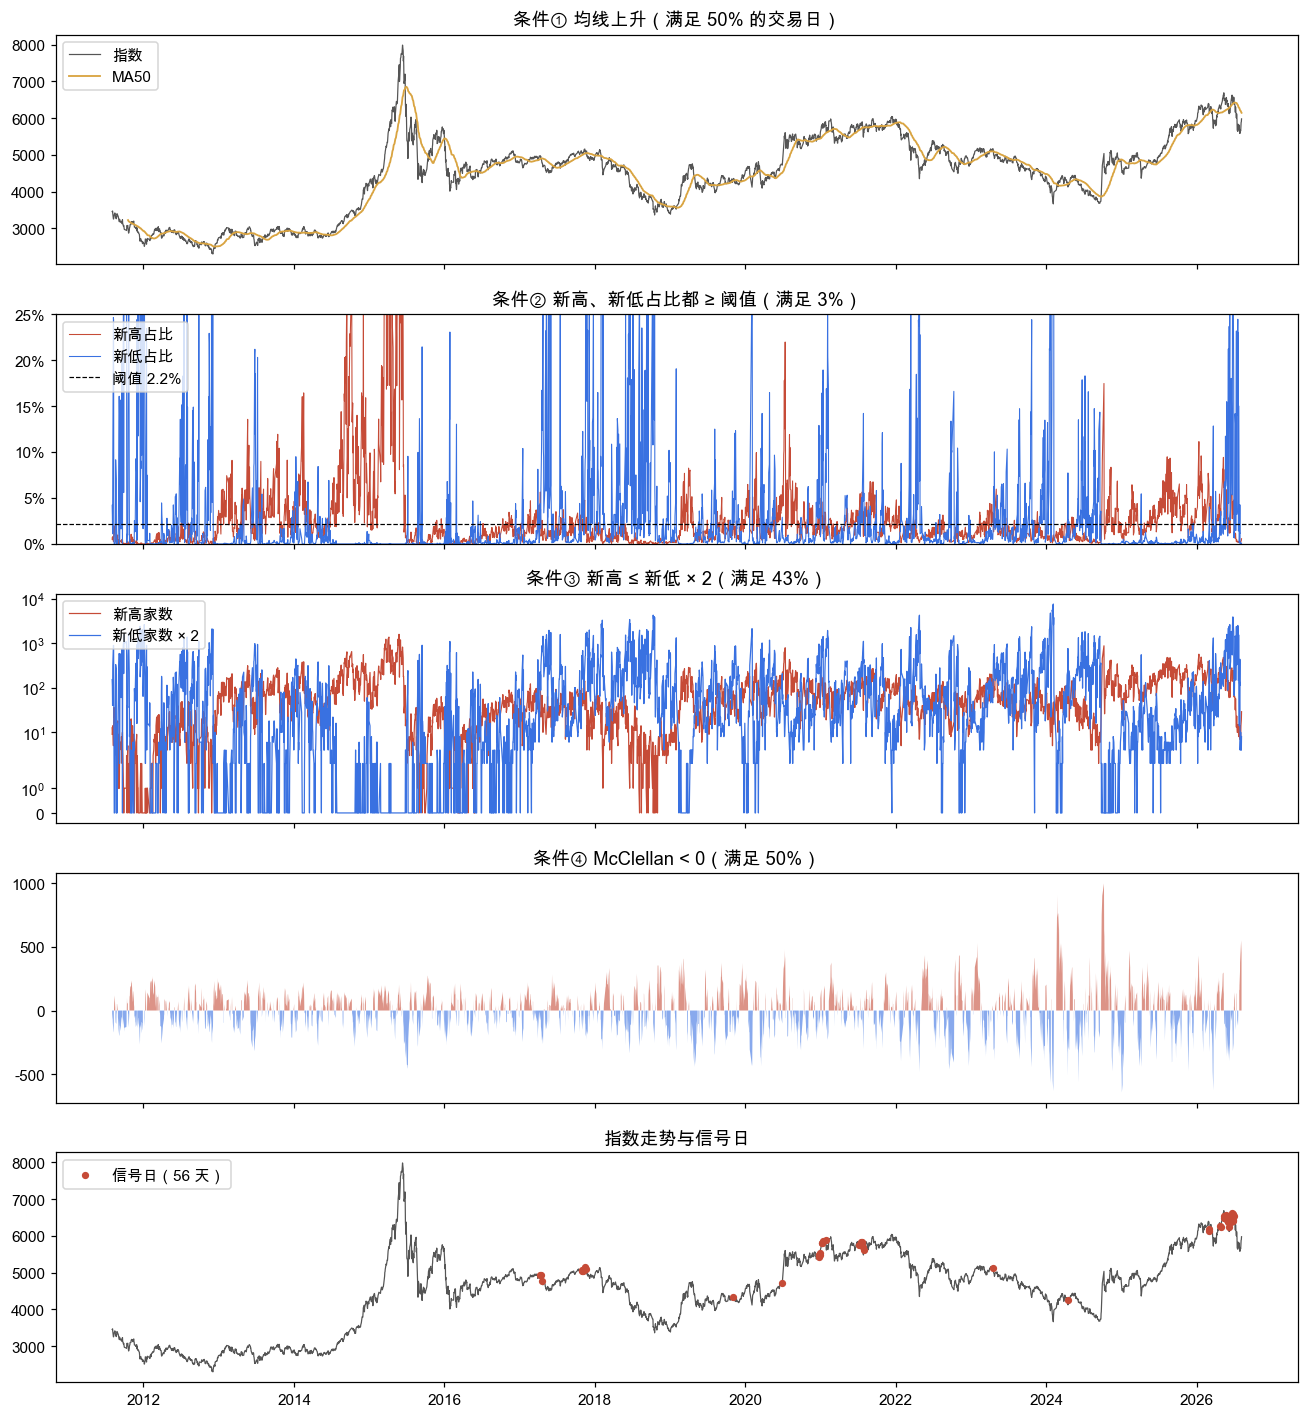

In [3]:
ma = omen.index_full.rolling(p.ma_period).mean().reindex(df.index)

fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True)
ax = axes[0]
ax.plot(df.index, df.index_close, lw=0.8, color='#555', label='指数')
ax.plot(df.index, ma, lw=1.2, color='#D9A441', label=f'MA{p.ma_period}')
ax.set_title(f'条件① 均线上升（满足 {df.cond1.mean():.0%} 的交易日）'); ax.legend(loc='upper left')

ax = axes[1]
ax.plot(df.index, df.high_ratio, lw=0.7, color='#C64B37', label='新高占比')
ax.plot(df.index, df.low_ratio, lw=0.7, color='#3971E1', label='新低占比')
ax.axhline(p.threshold, color='k', ls='--', lw=0.8, label=f'阈值 {p.threshold:.1%}')
ax.set_ylim(0, 0.25); ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set_title(f'条件② 新高、新低占比都 ≥ 阈值（满足 {df.cond2.mean():.0%}）'); ax.legend(loc='upper left')

ax = axes[2]
ax.plot(df.index, df.new_high, lw=0.8, color='#C64B37', label='新高家数')
ax.plot(df.index, df.new_low * p.hl_ratio, lw=0.8, color='#3971E1', label=f'新低家数 × {p.hl_ratio:g}')
ax.set_yscale('symlog'); ax.set_title(f'条件③ 新高 ≤ 新低 × {p.hl_ratio:g}（满足 {df.cond3.mean():.0%}）'); ax.legend(loc='upper left')

ax = axes[3]
ax.fill_between(df.index, df.mcclellan, 0, where=df.mcclellan < 0, color='#3971E1', alpha=0.6, lw=0)
ax.fill_between(df.index, df.mcclellan, 0, where=df.mcclellan >= 0, color='#C64B37', alpha=0.6, lw=0)
ax.set_title(f'条件④ McClellan < 0（满足 {df.cond4.mean():.0%}）')

ax = axes[4]
ax.plot(df.index, df.index_close, lw=0.8, color='#555')
sig = df[df.signal]
ax.scatter(sig.index, sig.index_close, s=14, color='#C64B37', zorder=3, label=f'信号日（{len(sig)} 天）')
ax.set_title('指数走势与信号日'); ax.legend(loc='upper left')
fig.tight_layout()

## 4. 聚成集群，计算后续回撤

- **有效集群**：窗口内信号数 ≥ 2；**单点**：只有 1 次信号，不参与统计。
- `dd_5d / dd_21d / dd_63d / dd_252d`：从确认日起未来 1 周 / 1 月 / 1 季 / 1 年的**峰谷最大回撤**。
- 等级按 252 日回撤划分：≤ −20% 较大回撤，≤ −10% 中型回调，≤ −5% 小幅回调；观察期未满一年的记为「近期信号」。

In [4]:
cl = evaluate(df, build_clusters(df, p), p)
show = cl[['cluster_id', 'type', 'start_date', 'end_date', 'confirm_date', 'signal_count',
           'dd_21d', 'dd_63d', 'dd_252d', 'level']].copy()
for c in ['dd_21d', 'dd_63d', 'dd_252d']:
    show[c] = show[c].map(lambda v: '' if pd.isna(v) else f'{v:.1%}')
for c in ['start_date', 'end_date', 'confirm_date']:
    show[c] = show[c].dt.strftime('%Y-%m-%d').fillna('')
show

,cluster_id,type,start_date,end_date,confirm_date,signal_count,dd_21d,dd_63d,dd_252d,level
0,1,有效集群,2017-04-10,2017-04-20,2017-04-12,3,-8.7%,-9.1%,-13.6%,中型回调
1,2,有效集群,2017-10-30,2017-11-21,2017-10-31,6,-4.8%,-6.1%,-34.8%,较大回撤
2,3,单点,2019-11-04,2019-11-04,,1,-3.9%,-12.0%,-14.9%,中型回调
3,4,单点,2020-06-29,2020-06-29,,1,-7.8%,-7.8%,-11.0%,中型回调
4,5,有效集群,2020-12-23,2021-01-25,2020-12-24,9,-2.0%,-11.0%,-11.0%,中型回调
5,6,有效集群,2021-07-08,2021-07-29,2021-07-15,8,-7.1%,-7.1%,-28.0%,较大回撤
6,7,单点,2023-04-20,2023-04-20,,1,-5.7%,-6.9%,-28.4%,较大回撤
7,8,单点,2024-04-15,2024-04-15,,1,-2.9%,-11.6%,-17.2%,中型回调
8,9,有效集群,2026-03-03,2026-03-04,2026-03-04,2,-9.3%,-9.3%,,近期信号
9,10,有效集群,2026-04-24,2026-06-18,2026-04-28,17,-5.5%,-16.5%,,近期信号


## 5. 命中率 vs 基准率（核心结论）

研报只报告命中率，例如「有效集群之后一年内出现 ≥10% 回撤的比例」。但这个数字单独看没有意义，**要和不看信号、随便挑一天的概率（基准率）对比**：

- **基准率（全样本）**：每一天都当作信号日，未来同一窗口出现同等回撤的比例。
- **基准率（趋势向上日）**：只在条件①成立的日子里抽样，扣除「趋势过滤」本身的贡献。
- **超额 = 命中率 − 基准率**。超额接近 0，说明信号没有提供额外信息。

In [5]:
m = summarize(df, cl, p)
rows = []
for w in p.dd_windows:
    h, ba, bu = m['window_hits'].get(w), m['baseline_all'].get(w), m['baseline_uptrend'].get(w)
    if not h:
        continue
    rows.append({'窗口(交易日)': w, '集群数': h['n'],
                 '命中率 ≤-10%': h['rate_mid'], '基准率 全样本': ba['p_mid'], '基准率 趋势向上': bu['p_mid'],
                 '超额': h['rate_mid'] - ba['p_mid'],
                 '命中率 ≤-20%': h['rate_big'], '基准率 ≤-20%': ba['p_big'],
                 '超额 ≤-20%': h['rate_big'] - ba['p_big']})
hit = pd.DataFrame(rows).set_index('窗口(交易日)')
hit.style.format({c: '{:.0%}' for c in hit.columns if c != '集群数'})

,集群数,命中率 ≤-10%,基准率 全样本,基准率 趋势向上,超额,命中率 ≤-20%,基准率 ≤-20%,超额 ≤-20%
窗口(交易日),,,,,,,,
5,7,0%,1%,1%,-1%,0%,0%,-0%
21,7,14%,13%,11%,2%,0%,2%,-2%
63,6,33%,43%,38%,-10%,0%,7%,-7%
252,4,100%,96%,97%,4%,50%,38%,12%


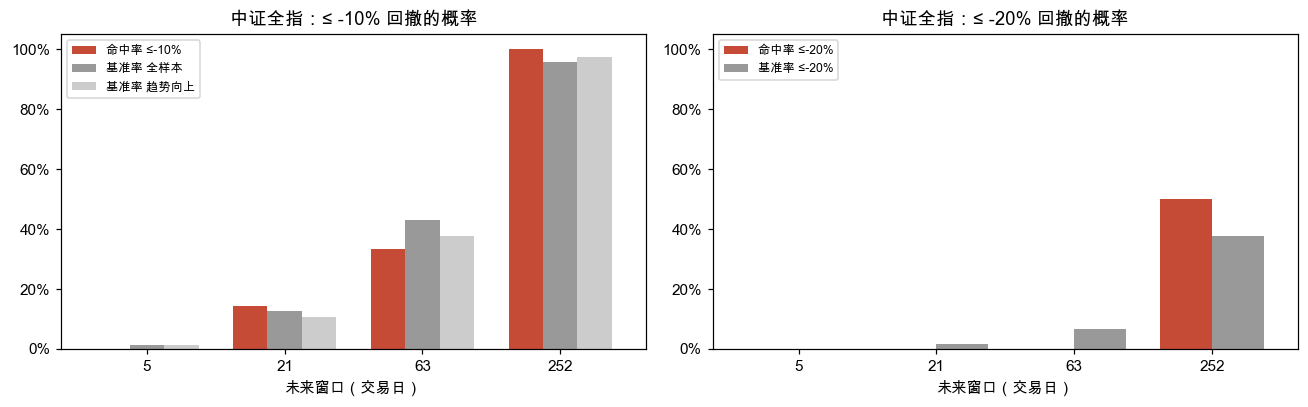

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (lab, cols) in zip(axes, [('≤ -10% 回撤', ['命中率 ≤-10%', '基准率 全样本', '基准率 趋势向上']),
                                    ('≤ -20% 回撤', ['命中率 ≤-20%', '基准率 ≤-20%'])]):
    hit[cols].plot.bar(ax=ax, rot=0, width=0.75, color=['#C64B37', '#999', '#ccc'][:len(cols)])
    ax.set_title(f'{s.name}：{lab}的概率'); ax.set_xlabel('未来窗口（交易日）')
    ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8, loc='upper left')
fig.tight_layout()

## 6. 案例：2015 年为什么没有信号

2015 年 6 月是 A 股的大顶，但指标没有触发。把顶部前后的逐日数据列出来，就能看到卡在哪：

In [7]:
win = df.loc['2015-06-08':'2015-07-10', ['index_close', 'cond1', 'high_ratio', 'low_ratio',
                                         'cond2', 'mcclellan', 'cond4', 'signal']]
print('2015-06 ~ 2015-09 条件②成立的天数：', int(df.loc['2015-06':'2015-09', 'cond2'].sum()))
win.style.format({'index_close': '{:,.0f}', 'high_ratio': '{:.1%}', 'low_ratio': '{:.1%}',
                            'mcclellan': '{:,.0f}'})

2015-06 ~ 2015-09 条件②成立的天数： 0


,index_close,cond1,high_ratio,low_ratio,cond2,mcclellan,cond4,signal
2015-06-08 00:00:00,"7,756",True,21.7%,0.0%,False,-26,True,False
2015-06-09 00:00:00,"7,732",True,15.7%,0.0%,False,-53,True,False
2015-06-10 00:00:00,"7,814",True,20.4%,0.0%,False,-13,True,False
2015-06-11 00:00:00,"7,892",True,33.4%,0.0%,False,5,False,False
2015-06-12 00:00:00,"7,984",True,38.9%,0.0%,False,20,False,False
2015-06-15 00:00:00,"7,830",True,22.2%,0.0%,False,-44,True,False
2015-06-16 00:00:00,"7,550",True,8.4%,0.0%,False,-135,True,False
2015-06-17 00:00:00,"7,687",True,8.6%,0.0%,False,-83,True,False
2015-06-18 00:00:00,"7,412",True,6.0%,0.0%,False,-167,True,False
2015-06-19 00:00:00,"6,943",True,1.3%,0.0%,False,-263,True,False


条件②要求新高、新低占比**同一天都** ≥ 2.2%，而 2015 年从「普涨」到「普跌」几乎没有过渡：

- 6 月中旬顶部：新高占比 30%~40%，新低占比接近 0%（几乎没有股票在创 52 周新低）。
- 6 月下旬下跌：新高占比迅速掉到 1% 以下，而新低占比仍接近 0%。
- 7 月 7~8 日：新低占比才跳到 5%~10%，但这时新高占比已不足 0.5%，而且条件①在 7 月 3 日已经失效（均线掉头）。

所以「新高和新低同时大量出现」的市场分化阶段根本没出现过，条件②一天都没成立。这是指标本身的盲区（齐涨齐跌、闪崩式行情），不是计算错误。

## 7. 五个指数汇总

每个指数的条件①和回撤用它自己的指数，条件②③④用对应的股票池：中证全指（全市场）、上证综指（仅沪市）、沪深300 / 中证500 / 中证1000（各自成分股）。

In [8]:
store, cache = _make_store(), BreadthCache()
rows = []
for key, st in STRATEGIES.items():
    pn = Panel(state_rule=st.state_rule, exclude_boards=st.params.exclude_boards,
               include_exchanges=st.params.include_exchanges)
    o = Omen(st, pn, store, cache)
    d = o.compute(st.start or config.START, pn.last_date.strftime('%Y-%m-%d'))
    c = evaluate(d, build_clusters(d, st.params), st.params)
    mm = summarize(d, c, st.params)
    ba = mm['baseline_all'][st.params.grade_window]
    rows.append({'指数': st.name, '起点': f'{d.index[0]:%Y-%m}', '信号天数': mm['signal_days'],
                 '有效集群': mm['n_clusters_valid'], '可评估': mm['n_gradable'],
                 '命中率 ≤-10%': mm['hit_rate'], '基准率 ≤-10%': ba['p_mid'],
                 '命中率 ≤-20%': mm['hit_rate_big'], '基准率 ≤-20%': ba['p_big']})
summary = pd.DataFrame(rows).set_index('指数')
summary['超额 ≤-10%'] = summary['命中率 ≤-10%'] - summary['基准率 ≤-10%']
summary['超额 ≤-20%'] = summary['命中率 ≤-20%'] - summary['基准率 ≤-20%']
summary.style.format({c: '{:.0%}' for c in summary.columns if '率' in c or '超额' in c})

[Store] 纯本地模式, 不联网



[中证全指] 计算宽度指标...



[上证综指] 计算宽度指标...



[沪深300] 计算宽度指标...



[中证500] 计算宽度指标...



[中证1000] 计算宽度指标...


,起点,信号天数,有效集群,可评估,命中率 ≤-10%,基准率 ≤-10%,命中率 ≤-20%,基准率 ≤-20%,超额 ≤-10%,超额 ≤-20%
指数,,,,,,,,,,
中证全指,2011-08,56,7,4,100%,96%,50%,38%,4%,12%
上证综指,2005-01,82,13,10,80%,85%,50%,44%,-5%,6%
沪深300,2005-04,134,19,14,100%,91%,50%,54%,9%,-4%
中证500,2007-01,85,12,9,89%,96%,56%,59%,-7%,-3%
中证1000,2014-10,53,7,4,100%,100%,100%,64%,0%,36%


## 8. 结论与局限

**结论：在 A 股上，兴登堡预兆没有表现出稳定的预警能力。**

- **命中率看着高，但基准率同样高。** 252 日窗口下 ≤ −10% 回撤的基准率在 85%~100%，A 股一年内几乎必然出现这种幅度的回撤。各指数命中率与基准率之差在 −7 到 +9 个百分点之间，有正有负。
- **更严格的 ≤ −20% 口径方向不一致。** 超额从 −4 到 +36 个百分点不等，最大的 +36 来自只有 4 个可评估集群的中证1000，偶然性很大。
- **短期没有优势。** 以中证全指为例，信号后 1 个月、1 个季度内的回撤概率并不高于随便挑一天。
- **最大的顶部恰恰漏掉了。** 2015 年这种齐涨齐跌的行情，条件②根本无法成立。
- 研报中「命中率 90%+」这类数字，主要反映的是 A 股回撤本身的高频率，而不是信号的预测力。

**局限**

- 可评估的有效集群只有个位数到十几个，命中率的置信区间很宽，结论不宜外推。
- 2.2% 阈值是按几千只股票的市场定的；沪深300 只有 300 只成分股，占比跳动大，规模指数的结果只适合和自己的历史比较。
- 参数可以在参数实验室里调，但样本这么小，调出「很准」的组合多半是过拟合。

本项目仅供研究，不构成投资建议。